**Célula 1 – setup:**

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

%load_ext autoreload
%autoreload 2

import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

from src.utils import set_seed, SEED, DIMS, get_splits, train_and_evaluate_classifier
from src.representation import fit_pca, pca_project, load_autoencoder, ae_encode

set_seed()
X_train, y_train, X_val, y_val, X_test, y_test = get_splits()
pca = fit_pca(X_train)

**Célula 2 – baseline: píxeis brutos (modelo já treinado):**

In [2]:
clf_raw = joblib.load("models/clf_raw.joblib")           
rows = [{
    "space": "raw pixels", "dim": 784,
    "val_acc": accuracy_score(y_val, clf_raw.predict(X_val)),
    "test_acc": accuracy_score(y_test, clf_raw.predict(X_test)),
    "train_time_s": pd.read_csv("results/tables/03_baseline_raw.csv")["train_time_s"][0],
}]
print(rows[0])

{'space': 'raw pixels', 'dim': 784, 'val_acc': 0.8559, 'test_acc': 0.8329, 'train_time_s': np.float64(820.4129337000195)}


**Célula 3 – PCA e autoencoder em todas as dimensões (pode demorar alguns minutos no total):**

In [3]:
for d in DIMS:
    # ---- PCA: projeta treino, validação e teste com o PCA ajustado SÓ no treino
    Ztr, Zva, Zte = (pca_project(pca, X, d) for X in (X_train, X_val, X_test))
    clf, test_acc, t = train_and_evaluate_classifier(Ztr, y_train, Zte, y_test)
    rows.append({"space": "PCA", "dim": d, "val_acc": accuracy_score(y_val, clf.predict(Zva)),
                 "test_acc": test_acc, "train_time_s": t})

    # ---- Autoencoder: código latente do modelo treinado na Etapa 6
    ae = load_autoencoder(d, f"models/ae_{d}.pt")
    Ztr, Zva, Zte = (ae_encode(ae, X) for X in (X_train, X_val, X_test))
    clf, test_acc, t = train_and_evaluate_classifier(Ztr, y_train, Zte, y_test)
    rows.append({"space": "AE", "dim": d, "val_acc": accuracy_score(y_val, clf.predict(Zva)),
                 "test_acc": test_acc, "train_time_s": t})

    print(f"d={d:3d} | PCA test={rows[-2]['test_acc']:.4f} | AE test={rows[-1]['test_acc']:.4f}")

d=  2 | PCA test=0.5093 | AE test=0.6166
d=  8 | PCA test=0.7302 | AE test=0.7664
d= 16 | PCA test=0.7870 | AE test=0.8012
d= 32 | PCA test=0.8154 | AE test=0.8234
d= 64 | PCA test=0.8324 | AE test=0.8434
d=128 | PCA test=0.8414 | AE test=0.8576


**Célula 4 – tabela final:**

In [4]:
clf_table = pd.DataFrame(rows)
print(clf_table.round(4).to_string(index=False))
clf_table.to_csv("results/tables/09_classification_table.csv", index=False)

wide = clf_table[clf_table.space != "raw pixels"].pivot(index="dim", columns="space", values="test_acc")
print("\nTest accuracy (raw pixels = {:.4f}):".format(rows[0]["test_acc"]))
print(wide.round(4).to_string())

     space  dim  val_acc  test_acc  train_time_s
raw pixels  784   0.8559    0.8329      820.4129
       PCA    2   0.5152    0.5093        0.5729
        AE    2   0.6263    0.6166        0.4146
       PCA    8   0.7407    0.7302        0.9030
        AE    8   0.7779    0.7664        0.7191
       PCA   16   0.8016    0.7870        0.9515
        AE   16   0.8208    0.8012        1.0495
       PCA   32   0.8295    0.8154        0.9890
        AE   32   0.8406    0.8234        1.7133
       PCA   64   0.8493    0.8324        1.3188
        AE   64   0.8619    0.8434        2.9467
       PCA  128   0.8631    0.8414        1.5292
        AE  128   0.8731    0.8576        5.1595

Test accuracy (raw pixels = 0.8329):
space      AE     PCA
dim                  
2      0.6166  0.5093
8      0.7664  0.7302
16     0.8012  0.7870
32     0.8234  0.8154
64     0.8434  0.8324
128    0.8576  0.8414


**Célula 5 – gráfico accuracy vs dimensão:**

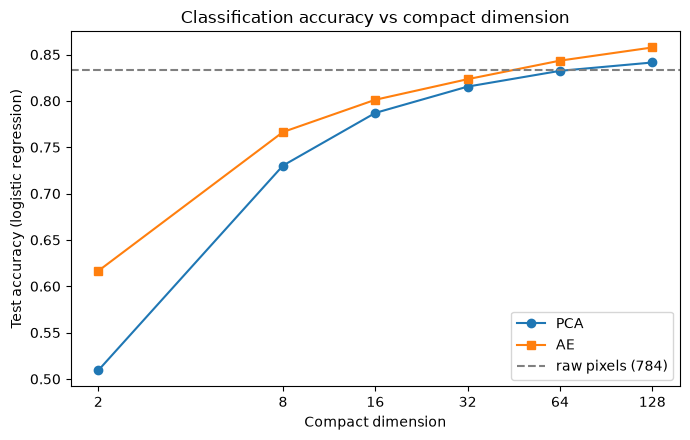

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for space, marker in [("PCA", "o"), ("AE", "s")]:
    sub = clf_table[clf_table.space == space]
    ax.plot(sub["dim"], sub["test_acc"], marker=marker, label=space)
ax.axhline(rows[0]["test_acc"], ls="--", color="gray", label="raw pixels (784)")   # baseline
ax.set_xscale("log", base=2)
ax.set_xticks(DIMS, labels=DIMS)
ax.set_xlabel("Compact dimension")
ax.set_ylabel("Test accuracy (logistic regression)")
ax.set_title("Classification accuracy vs compact dimension")
ax.legend()
plt.tight_layout()
plt.savefig("results/figures/09_accuracy_vs_dim.png", dpi=150, bbox_inches="tight")
plt.show()